# 11. External evaluation of fixed CNN and ViT models

Laboratory accuracy does not establish performance on photographs acquired outside
the training sources. Following the Lab Test and PlantDoc Field Dev comparison in
notebook 09, this experiment evaluates the same four fixed models on Tomato Field
Evaluation v1.

Within RQ2, the question is whether the domain-adapted CNN and ViT configurations
achieve higher observed performance than their laboratory baselines on this external
collection. No weights,
checkpoints or decision thresholds are selected using these external results.

## Environment and artifacts

Run with the project Python environment from the repository root or `notebooks/`.
Each execution saves a separate evaluation directory. Validation details and inference
transforms are retained with the outputs. An optional `PLANT_EXTERNAL_REFERENCE_RUN`
path enables comparison with an earlier run; no earlier execution is required.

In [1]:
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone
from zoneinfo import ZoneInfo
from uuid import uuid4
from html import escape
from urllib.parse import quote
import gc
import hashlib
import importlib.metadata
import json
import os
import platform
import subprocess
import sys
import traceback
from contextlib import redirect_stdout

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import warnings
with warnings.catch_warnings(record=True) as import_warnings:
    warnings.simplefilter("always")
    import torch
    import torchvision
    import timm
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import ResNet18_Weights, resnet18
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)
from IPython.display import display, Markdown, HTML

In [2]:
root_override = os.environ.get("PLANT_PROJECT_ROOT")
candidates = [Path(root_override)] if root_override else [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p.resolve() for p in candidates
                     if (p / "data/splits/label_map.json").is_file()
                     and (p / "notebooks/09_final_model_comparison.ipynb").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate repository; set PLANT_PROJECT_ROOT to its absolute path.")
DATA_ROOT = PROJECT_ROOT / "data/external_evaluation/tomato_field_eval_v1"
REVIEW_ROOT = PROJECT_ROOT / "docs/dataset_review/tomato_field_eval_v1"
SPLITS_DIR = PROJECT_ROOT / "data/splits"
RUN_ID = datetime.now(ZoneInfo("Asia/Ho_Chi_Minh")).strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:8]
OUTPUT_ROOT = PROJECT_ROOT / "outputs/external_evaluation/tomato_field_eval_v1" / RUN_ID
OUTPUT_ROOT.mkdir(parents=True, exist_ok=False)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
torch.set_num_threads(min(4, os.cpu_count() or 1))
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11})

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

VERSIONS = {name: importlib.metadata.version(name) for name in (
    "torch", "torchvision", "timm", "numpy", "pandas", "scikit-learn", "Pillow", "matplotlib"
)}

reference_path = os.environ.get("PLANT_EXTERNAL_REFERENCE_RUN")
REFERENCE_RUN = None
reference_protocol = None
if reference_path is not None:
    if not reference_path.strip():
        raise ValueError("PLANT_EXTERNAL_REFERENCE_RUN must name an evaluation directory.")
    REFERENCE_RUN = Path(reference_path).expanduser()
    if not REFERENCE_RUN.is_absolute():
        REFERENCE_RUN = PROJECT_ROOT / REFERENCE_RUN
    REFERENCE_RUN = REFERENCE_RUN.resolve()
    reference_protocol = json.loads((REFERENCE_RUN / "evaluation_protocol.json").read_text())
    assert reference_protocol["complete_four_model_evaluation"] is True
(OUTPUT_ROOT / "environment.log").write_text(
    json.dumps(VERSIONS, indent=2) + "\n" +
    "\n".join(f"{item.category.__name__}: {item.message}" for item in import_warnings), encoding="utf-8"
)
print("Evaluation device:", DEVICE)
print("Output directory:", OUTPUT_ROOT.relative_to(PROJECT_ROOT))

Evaluation device: cpu
Output directory: outputs/external_evaluation/tomato_field_eval_v1/20261125_163347_4ca8183f


## External dataset

The collection contains 62 selected tomato images across five classes. All 16 Healthy
photographs are self-collected; the 46 disease photographs have documented online
sources. Image types comprise 39 intact multi-leaf photographs, five intact single-leaf
photographs and 18 reviewed crops.

The acquisition metadata distinguishes field-like self-collected photographs (16),
online leaf reference photographs (45), and one experimental/potted image. Online
reference photographs are not assumed to follow a field-acquisition protocol.

In [3]:
validator = REVIEW_ROOT / "scripts/validate_dataset.py"
if validator.is_file():
    validation = subprocess.run(
        [sys.executable, str(validator), "--root", str(DATA_ROOT),
         "--review-root", str(REVIEW_ROOT)], capture_output=True, text=True,
    )
    (OUTPUT_ROOT / "dataset_validation.log").write_text(
        validation.stdout + validation.stderr, encoding="utf-8"
    )
    if validation.returncode:
        raise RuntimeError("Existing dataset validator failed; see dataset_validation.log")
    AUDIT_STATUS = "passed"
else:
    AUDIT_STATUS = "unavailable: local dataset_review validator and audit metadata absent"
    (OUTPUT_ROOT / "dataset_validation.log").write_text(AUDIT_STATUS, encoding="utf-8")

In [4]:
CANONICAL_MAP = {"Healthy": 0, "Early Blight": 1, "Late Blight": 2,
                 "Bacterial Spot": 3, "Septoria Leaf Spot": 4}
LABEL_MAP = json.loads((SPLITS_DIR / "label_map.json").read_text())
assert LABEL_MAP == CANONICAL_MAP, "Historical label map differs from the canonical mapping."
CLASS_NAMES = list(CANONICAL_MAP)
LABEL_IDS = list(range(5))
manifest = pd.read_csv(DATA_ROOT / "manifest.csv", keep_default_na=False)
assert len(manifest) == 62
for column in ("image_id", "image_path", "filename", "sha256"):
    assert manifest[column].is_unique, f"Duplicate {column}"
assert (manifest.class_name.map(LABEL_MAP) == manifest.label_id).all()
assert manifest.class_name.value_counts().to_dict() == {
    "Healthy": 16, "Early Blight": 13, "Late Blight": 11,
    "Bacterial Spot": 9, "Septoria Leaf Spot": 13,
}
assert manifest.source.value_counts().to_dict() == {"online_sources": 46, "self_collected": 16}
assert (manifest.loc[manifest.class_name.eq("Healthy"), "source"] == "self_collected").all()
assert (manifest.loc[~manifest.class_name.eq("Healthy"), "source"] == "online_sources").all()
assert manifest.source_stratum.value_counts().to_dict() == {
    "web_leaf_photo": 45, "self_collected_natural_context": 16, "web_potted_experimental": 1,
}
assert manifest.image_type.value_counts().to_dict() == {"multi_leaf": 39, "cropped": 18, "single_leaf": 5}
assert manifest.split.eq("external_test").all()

In [5]:
image_paths = []
for row in manifest.itertuples():
    relative = PurePosixPath(row.image_path)
    assert not relative.is_absolute() and ".." not in relative.parts and "\\" not in row.image_path
    path = (DATA_ROOT / row.image_path).resolve()
    assert path.is_relative_to(DATA_ROOT.resolve()) and path.is_file(), row.image_path
    assert path.name == row.filename
    assert sha256_file(path) == row.sha256, row.image_id
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        image.load()
        assert image.size == (row.width, row.height), row.image_id
    image_paths.append(path)
actual_images = {p.resolve() for p in (DATA_ROOT / "images").rglob("*") if p.is_file()}
assert actual_images == set(image_paths), "Image tree and manifest differ."
ignore_check = subprocess.run(
    ["git", "-C", str(PROJECT_ROOT), "check-ignore", "--stdin"],
    input="\n".join(str(p.relative_to(PROJECT_ROOT)) for p in image_paths) + "\n",
    text=True, capture_output=True, check=True,
)
assert len(ignore_check.stdout.splitlines()) == 62, "Some evaluation images are not ignored."
tracked_images = subprocess.check_output(
    ["git", "-C", str(PROJECT_ROOT), "ls-files", "data/external_evaluation/tomato_field_eval_v1/images"],
    text=True,
)
assert not tracked_images.strip(), "Evaluation images must not be tracked."
MANIFEST_SHA256 = sha256_file(DATA_ROOT / "manifest.csv")
manifest.to_csv(OUTPUT_ROOT / "evaluated_manifest.csv", index=False)
display(pd.DataFrame({"label_id": LABEL_IDS, "class_name": CLASS_NAMES,
                      "images": [int(manifest.class_name.eq(c).sum()) for c in CLASS_NAMES]}))

,label_id,class_name,images
0,0,Healthy,16
1,1,Early Blight,13
2,2,Late Blight,11
3,3,Bacterial Spot,9
4,4,Septoria Leaf Spot,13


In [6]:
composition = pd.crosstab([manifest.source_stratum, manifest.image_type], manifest.class_name)
composition = composition.reindex(columns=CLASS_NAMES, fill_value=0)
composition["images"] = composition.sum(axis=1)
composition.to_csv(OUTPUT_ROOT / "dataset_composition.csv")
display(composition)

class_name                                  Healthy  Early Blight  \
source_stratum                 image_type                           
self_collected_natural_context cropped            8             0   
                               multi_leaf         8             0   
web_leaf_photo                 cropped            0             1   
                               multi_leaf         0            11   
                               single_leaf        0             1   
web_potted_experimental        cropped            0             0   

class_name                                  Late Blight  Bacterial Spot  \
source_stratum                 image_type                                 
self_collected_natural_context cropped                0               0   
                               multi_leaf             0               0   
web_leaf_photo                 cropped                5               1   
                               multi_leaf             6               6   
                               single_leaf            0               1   
web_potted_experimental        cropped                0               1   

class_name                                  Septoria Leaf Spot  images  
source_stratum                 image_type                               
self_collected_natural_context cropped                       0       8  
                               multi_leaf                    0       8  
web_leaf_photo                 cropped                       2       9  
                               multi_leaf                    8      31  
                               single_leaf                   3       5  
web_potted_experimental        cropped                       0       1

Healthy labels reflect team visual review and disease labels verified source captions,
rather than laboratory-confirmed diagnoses. Acquisition source and class are confounded;
this limits interpretation of the pooled scores.

## Evaluation methodology

The models and inference transforms follow notebooks 02–03 and 08–10. The adapted
CNN is the geometric-initialized mixed model from notebook 08, not the geometric
source model alone. Its baseline-to-mixed contrast includes both stages.

| Model | Architecture | Inference transform |
|---|---|---|
| ResNet18 laboratory baseline | ResNet18, five-class head | Original torchvision ImageNet transform |
| ViT-Small laboratory baseline | `vit_small_patch16_224.augreg_in1k` | Saved timm evaluation configuration |
| ResNet18 geometric + mixed | Same ResNet18 architecture | Same torchvision transform |
| ViT-Small mixed | Same ViT-Small architecture | Configuration from its verified laboratory source checkpoint |

ResNet18 uses bilinear resize to 256, center crop to 224 and ImageNet normalization.
ViT uses its saved bicubic, `crop_pct=0.9`, 224-input configuration with mean and
standard deviation 0.5 per channel. Class order, source-checkpoint hashes and historical
selection-manifest hashes are checked before strict weight loading.

In [7]:
# Paths are taken from notebooks 02–03 and 09–10, not inferred from arbitrary file names.
DRIVE_ROOT = Path(os.environ.get(
    "PLANT_DRIVE_ROOT", "/content/drive/MyDrive/plant-disease-diagnosis"
))
USE_DRIVE = DRIVE_ROOT.is_dir()
MODEL_SPECS = {
    "resnet_lab": {
        "model": "ResNet18 · Lab baseline", "architecture": "resnet18", "phase": "lab_only",
        "checkpoint": DRIVE_ROOT / "resnet18_baseline/resnet18_lab_best.pt" if USE_DRIVE
                      else PROJECT_ROOT / "models/resnet18_lab_best.pt",
        "batch_size": 32,
    },
    "vit_lab": {
        "model": "ViT-Small · Lab baseline", "architecture": "vit_small_patch16_224.augreg_in1k",
        "phase": "lab_only",
        "checkpoint": DRIVE_ROOT / "vit_small_baseline/vit_small_lab_best.pt" if USE_DRIVE
                      else PROJECT_ROOT / "models/vit_small_lab_best.pt",
        "batch_size": 16,
    },
    "resnet_mixed": {
        "model": "ResNet18 · Geometric + Mixed", "architecture": "resnet18", "phase": "mixed_domain",
        "experiment": "R2_resnet_geometric",
        "checkpoint": DRIVE_ROOT / "mixed_domain_verified/R2_resnet_geometric/mixed_domain_best.pt"
                      if USE_DRIVE else PROJECT_ROOT / "models/resnet18_geometric_mixed_best.pt",
        "batch_size": 32,
    },
    "vit_mixed": {
        "model": "ViT-Small · Mixed", "architecture": "vit_small_patch16_224.augreg_in1k",
        "phase": "mixed_domain", "experiment": "V1_vit_small",
        "checkpoint": DRIVE_ROOT / "mixed_domain_verified/V1_vit_small/mixed_domain_best.pt"
                      if USE_DRIVE else PROJECT_ROOT / "models/vit_small_mixed_best.pt",
        "batch_size": 16,
    },
}
MODEL_SPECS["resnet_lab"]["source_checkpoint"] = MODEL_SPECS["resnet_lab"]["checkpoint"]
MODEL_SPECS["vit_lab"]["source_checkpoint"] = MODEL_SPECS["vit_lab"]["checkpoint"]
MODEL_SPECS["resnet_mixed"]["source_checkpoint"] = (
    DRIVE_ROOT / "resnet18_aug_geometric/resnet18_best.pt" if USE_DRIVE
    else PROJECT_ROOT / "models/resnet18_aug_geometric_best.pt"
)
MODEL_SPECS["vit_mixed"]["source_checkpoint"] = MODEL_SPECS["vit_lab"]["checkpoint"]

In [8]:
# Edit these explicit paths if the same checkpoints are stored elsewhere.
availability = []
for key, spec in MODEL_SPECS.items():
    missing = sorted({str(spec[field]) for field in ("checkpoint", "source_checkpoint")
                      if not spec[field].is_file()})
    availability.append({"model_key": key, "model": spec["model"],
                         "status": "missing_checkpoint" if missing else "ready",
                         "missing_prerequisites": " | ".join(missing)})
availability = pd.DataFrame(availability)
availability.to_csv(OUTPUT_ROOT / "checkpoint_availability.csv", index=False)
SPLIT_HASHES = {name: sha256_file(SPLITS_DIR / f"{name}.csv")
                for name in ("field_dev", "lab_val", "lab_test")}
assert availability.status.eq("ready").all(), availability.to_string(index=False)
if reference_protocol is not None:
    assert reference_protocol["manifest_sha256"] == MANIFEST_SHA256
    assert reference_protocol["class_mapping"] == LABEL_MAP
    for key, spec in MODEL_SPECS.items():
        recorded = reference_protocol["checkpoints_and_preprocessing"][key]
        assert sha256_file(spec["checkpoint"]) == recorded["checkpoint_sha256"], key
        assert sha256_file(spec["source_checkpoint"]) == recorded["source_checkpoint_sha256"], key

In [9]:
class ExternalDataset(Dataset):
    def __init__(self, transform):
        self.transform = transform

    def __len__(self):
        return len(manifest)

    def __getitem__(self, index):
        with Image.open(image_paths[index]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            tensor = self.transform(image)
        assert tensor.shape == (3, 224, 224)
        return tensor, int(manifest.iloc[index].label_id)

In [10]:
def load_fixed_model(key):
    spec = MODEL_SPECS[key]
    state = torch.load(spec["checkpoint"], map_location="cpu", weights_only=True)
    source = torch.load(spec["source_checkpoint"], map_location="cpu", weights_only=True)
    for record in (state, source):
        assert list(record["class_names"]) == CLASS_NAMES, f"Label order mismatch: {key}"
        assert record["architecture"] == spec["architecture"], f"Architecture mismatch: {key}"
    if spec["phase"] == "mixed_domain":
        assert state["adaptation_type"] == "balanced_mixed_domain"
        assert state["experiment"] == spec["experiment"]
        assert state["field_dev_sha256"] == SPLIT_HASHES["field_dev"]
        assert state["manifest_sha256"]["lab_val"] == SPLIT_HASHES["lab_val"]
        assert state["source_checkpoint_sha256"] == sha256_file(spec["source_checkpoint"])
    if spec["architecture"] == "resnet18":
        assert source["pretrained_weights"] == "IMAGENET1K_V1"
        model = resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, 5)
        transform = ResNet18_Weights.IMAGENET1K_V1.transforms()
        config = {"source": "torchvision.ResNet18_Weights.IMAGENET1K_V1.transforms"}
    else:
        assert source["pretrained_weights"] == "augreg_in1k"
        config = source["preprocessing_config"]
        assert tuple(config["input_size"]) == (3, 224, 224)
        model = timm.create_model(spec["architecture"], pretrained=False, num_classes=5)
        transform = timm.data.create_transform(**config, is_training=False)
    model.load_state_dict(state["model_state_dict"], strict=True)
    model.to(DEVICE).eval()
    model.requires_grad_(False)
    provenance = {
        "checkpoint": str(spec["checkpoint"]), "checkpoint_sha256": sha256_file(spec["checkpoint"]),
        "source_checkpoint": str(spec["source_checkpoint"]),
        "source_checkpoint_sha256": sha256_file(spec["source_checkpoint"]),
        "architecture": spec["architecture"], "phase": spec["phase"],
        "preprocessing_config": config, "transform": repr(transform),
        "checkpoint_metadata": {k: v for k, v in state.items() if k != "model_state_dict"},
    }
    return model, transform, provenance

In [11]:
def score_predictions(frame):
    truth, prediction = frame.label_id.to_numpy(), frame.predicted_label_id.to_numpy()
    return {
        "images": len(frame), "correct": int(np.sum(truth == prediction)),
        "accuracy": float(accuracy_score(truth, prediction)),
        "macro_f1": float(f1_score(truth, prediction, labels=LABEL_IDS,
                                  average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(truth, prediction, labels=LABEL_IDS,
                                     average="weighted", zero_division=0)),
    }

### Fixed-model inference

All models receive the same 62 images in manifest order, with EXIF orientation and
RGB conversion. Evaluation uses float32 inference, five-class argmax and no test-time
augmentation. Confidence is the maximum uncalibrated softmax probability.

Accuracy measures the proportion correct; macro-F1 weights the five classes equally;
weighted-F1 weights them by support. Per-class precision, recall and F1 use the same
canonical label order, with undefined values set to zero. No additional training or
checkpoint selection is performed.

In [12]:
def infer_external(key):
    spec = MODEL_SPECS[key]
    model, transform, provenance = load_fixed_model(key)
    print(key, "\n", transform)
    loader = DataLoader(ExternalDataset(transform), batch_size=spec["batch_size"],
                        shuffle=False, num_workers=0, pin_memory=DEVICE.type == "cuda")
    probabilities, labels = [], []
    with torch.inference_mode():
        for images, targets in loader:
            logits = model(images.to(DEVICE))
            assert logits.shape == (len(images), 5) and torch.isfinite(logits).all()
            probabilities.append(logits.float().softmax(dim=1).cpu().numpy())
            labels.extend(targets.tolist())
    probabilities = np.concatenate(probabilities)
    assert probabilities.shape == (62, 5)
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-6)
    assert labels == manifest.label_id.tolist()
    result = manifest.copy()
    result["model_key"], result["model"] = key, spec["model"]
    result["ground_truth_label"] = result.class_name
    result["predicted_label_id"] = probabilities.argmax(axis=1)
    result["predicted_label"] = result.predicted_label_id.map(dict(enumerate(CLASS_NAMES)))
    result["confidence"] = probabilities.max(axis=1)
    result["correct"] = result.label_id == result.predicted_label_id
    for label in LABEL_IDS:
        result[f"probability_label_{label}"] = probabilities[:, label]
    del model, loader
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result, provenance

In [13]:
prediction_frames, provenance_records, status_rows, per_class_rows = {}, {}, [], []
with (OUTPUT_ROOT / "inference.log").open("w") as log, redirect_stdout(log):
    for key, spec in MODEL_SPECS.items():
        try:
            result, provenance = infer_external(key)
        except Exception:
            (OUTPUT_ROOT / f"runtime_error_{key}.txt").write_text(traceback.format_exc())
            raise
        result.to_csv(OUTPUT_ROOT / f"predictions_{key}.csv", index=False)
        report = classification_report(
            result.label_id, result.predicted_label_id, labels=LABEL_IDS,
            target_names=CLASS_NAMES, output_dict=True, zero_division=0,
        )
        (OUTPUT_ROOT / f"classification_report_{key}.json").write_text(json.dumps(report, indent=2))
        for name in CLASS_NAMES:
            per_class_rows.append({"model_key": key, "model": spec["model"], "class_name": name,
                                   "support": int(report[name]["support"]),
                                   "precision": report[name]["precision"], "recall": report[name]["recall"],
                                   "f1": report[name]["f1-score"]})
        status_rows.append({"model_key": key, "model": spec["model"], "phase": spec["phase"],
                            "status": "evaluated", "detail": "", **score_predictions(result)})
        prediction_frames[key], provenance_records[key] = result, provenance

summary = pd.DataFrame(status_rows)
per_class = pd.DataFrame(per_class_rows)
predictions = pd.concat(prediction_frames.values(), ignore_index=True)
assert len(predictions) == 248 and summary.images.eq(62).all()
summary.to_csv(OUTPUT_ROOT / "model_summary.csv", index=False)
per_class.to_csv(OUTPUT_ROOT / "per_class_metrics.csv", index=False)
predictions.to_csv(OUTPUT_ROOT / "per_image_predictions.csv", index=False)

In [14]:
if REFERENCE_RUN is not None:
    reproduction_checks = []
    for key, result in prediction_frames.items():
        prior = pd.read_csv(REFERENCE_RUN / f"predictions_{key}.csv").set_index("image_id").loc[result.image_id]
        assert np.array_equal(prior.label_id, result.label_id)
        assert np.array_equal(prior.predicted_label_id, result.predicted_label_id), key
        probability_columns = [f"probability_label_{i}" for i in LABEL_IDS]
        max_difference = float(np.max(np.abs(prior[probability_columns].to_numpy() - result[probability_columns].to_numpy())))
        assert max_difference <= 2e-5, (key, max_difference)
        for metric, value in score_predictions(result).items():
            saved = pd.read_csv(REFERENCE_RUN / "model_summary.csv").set_index("model_key").loc[key, metric]
            assert np.isclose(value, saved, atol=1e-8), (key, metric)
        reproduction_checks.append({"model_key": key, "identical_predicted_labels": True,
                                    "max_probability_difference": max_difference})
    pd.DataFrame(reproduction_checks).to_csv(OUTPUT_ROOT / "reference_reproduction.csv", index=False)

## Experimental results

The table and figures compare the four fixed checkpoints on the external collection.
All metrics below are calculated from the image-level predictions.

,model,images,correct,accuracy,macro_f1,weighted_f1
0,ResNet18 · Lab baseline,62,19,0.3065,0.2406,0.2283
1,ViT-Small · Lab baseline,62,27,0.4355,0.4157,0.4202
2,ResNet18 · Geometric + Mixed,62,33,0.5323,0.4882,0.5052
3,ViT-Small · Mixed,62,32,0.5161,0.4808,0.5024


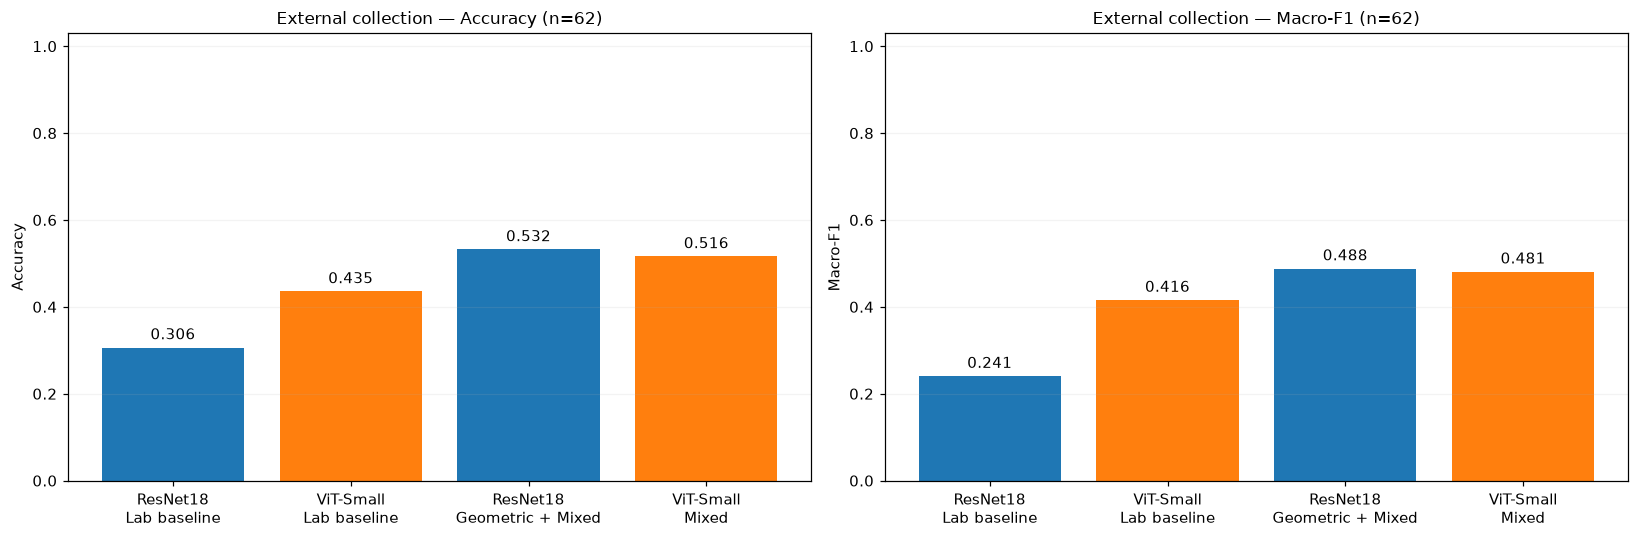

In [15]:
display(summary[["model", "images", "correct", "accuracy", "macro_f1", "weighted_f1"]].round(4))
model_labels = ["ResNet18\nLab baseline", "ViT-Small\nLab baseline",
                "ResNet18\nGeometric + Mixed", "ViT-Small\nMixed"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in zip(axes, ("accuracy", "macro_f1"), ("Accuracy", "Macro-F1")):
    bars = ax.bar(np.arange(4), summary[metric], color=["#1f77b4", "#ff7f0e", "#1f77b4", "#ff7f0e"])
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set(xticks=np.arange(4), xticklabels=model_labels, ylabel=title, ylim=(0, 1.03),
           title=f"External collection — {title} (n=62)")
    ax.grid(axis="y", alpha=0.15)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "external_model_comparison.png", dpi=160)
plt.show()
plt.close(fig)

In [16]:
scores = summary.set_index("model_key")
best = summary.sort_values(["accuracy", "macro_f1"], ascending=False).iloc[0]
accuracy_gains = {arch: scores.loc[f"{arch}_mixed", "accuracy"] - scores.loc[f"{arch}_lab", "accuracy"]
                  for arch in ("resnet", "vit")}
display(Markdown(
    f"Mixed-domain accuracy exceeds the respective laboratory baseline by "
    f"{100*accuracy_gains['resnet']:.2f} percentage points for ResNet18 and "
    f"{100*accuracy_gains['vit']:.2f} points for ViT-Small. "
    f"{best['model']} has the highest observed accuracy ({best.accuracy:.2%}) "
    f"and macro-F1 ({best.macro_f1:.4f}) among these fixed configurations."
))

Mixed-domain accuracy exceeds the respective laboratory baseline by 22.58 percentage points for ResNet18 and 8.06 points for ViT-Small. ResNet18 · Geometric + Mixed has the highest observed accuracy (53.23%) and macro-F1 (0.4882) among these fixed configurations.

### Per-class performance

Overall gains can conceal losses in individual classes. The report retains precision,
recall, F1 and support; the confusion matrices show where the errors are assigned.

support  precision  recall  \
class_name         model                                                      
Healthy            ResNet18 · Lab baseline            16     0.0000  0.0000   
                   ViT-Small · Lab baseline           16     1.0000  0.3125   
                   ResNet18 · Geometric + Mixed       16     0.8000  0.7500   
                   ViT-Small · Mixed                  16     0.9286  0.8125   
Early Blight       ResNet18 · Lab baseline            13     0.2821  0.8462   
                   ViT-Small · Lab baseline           13     0.3750  0.2308   
                   ResNet18 · Geometric + Mixed       13     0.5000  0.0769   
                   ViT-Small · Mixed                  13     0.4000  0.1538   
Late Blight        ResNet18 · Lab baseline            11     0.2778  0.4545   
                   ViT-Small · Lab baseline           11     0.4211  0.7273   
                   ResNet18 · Geometric + Mixed       11     0.4211  0.7273   
                   ViT-Small · Mixed                  11     0.4444  0.7273   
Bacterial Spot     ResNet18 · Lab baseline             9     1.0000  0.1111   
                   ViT-Small · Lab baseline            9     0.6667  0.2222   
                   ResNet18 · Geometric + Mixed        9     0.3333  0.5556   
                   ViT-Small · Mixed                   9     0.3125  0.5556   
Septoria Leaf Spot ResNet18 · Lab baseline            13     0.5000  0.1538   
                   ViT-Small · Lab baseline           13     0.3333  0.6923   
                   ResNet18 · Geometric + Mixed       13     0.6364  0.5385   
                   ViT-Small · Mixed                  13     0.4444  0.3077   

                                                     f1  
class_name         model                                 
Healthy            ResNet18 · Lab baseline       0.0000  
                   ViT-Small · Lab baseline      0.4762  
                   ResNet18 · Geometric + Mixed  0.7742  
                   ViT-Small · Mixed             0.8667  
Early Blight       ResNet18 · Lab baseline       0.4231  
                   ViT-Small · Lab baseline      0.2857  
                   ResNet18 · Geometric + Mixed  0.1333  
                   ViT-Small · Mixed             0.2222  
Late Blight        ResNet18 · Lab baseline       0.3448  
                   ViT-Small · Lab baseline      0.5333  
                   ResNet18 · Geometric + Mixed  0.5333  
                   ViT-Small · Mixed             0.5517  
Bacterial Spot     ResNet18 · Lab baseline       0.2000  
                   ViT-Small · Lab baseline      0.3333  
                   ResNet18 · Geometric + Mixed  0.4167  
                   ViT-Small · Mixed             0.4000  
Septoria Leaf Spot ResNet18 · Lab baseline       0.2353  
                   ViT-Small · Lab baseline      0.4500  
                   ResNet18 · Geometric + Mixed  0.5833  
                   ViT-Small · Mixed             0.3636

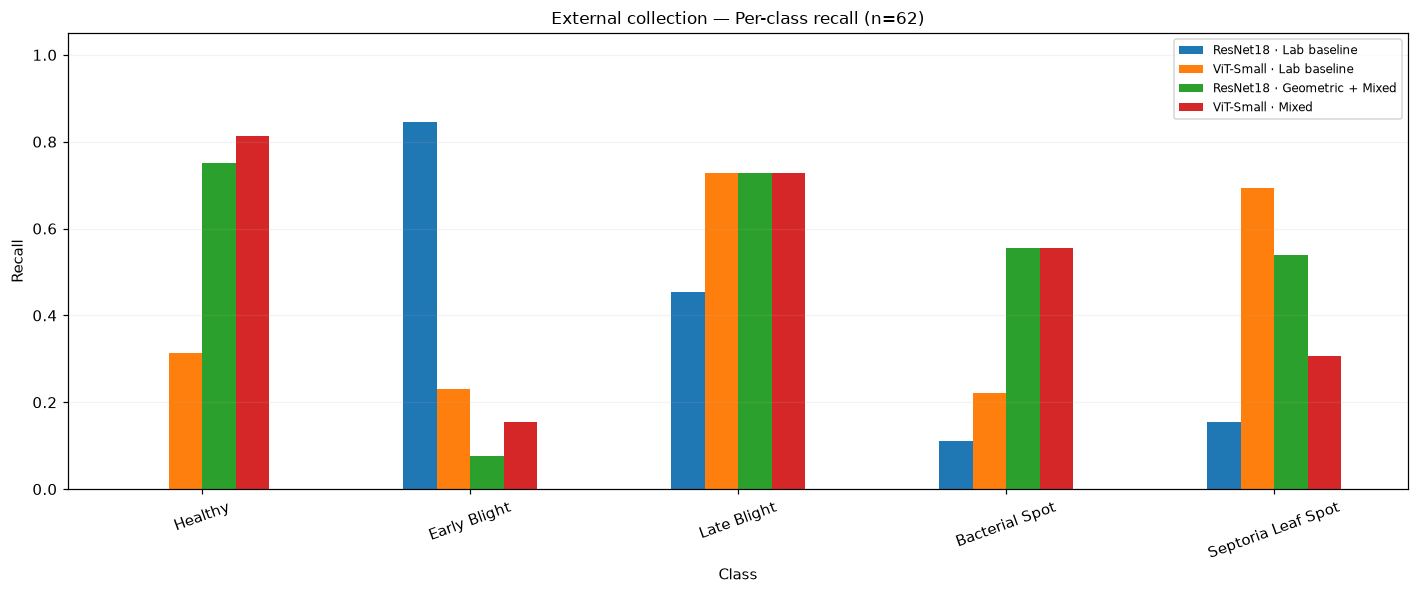

In [17]:
class_order = pd.Categorical(per_class.class_name, categories=CLASS_NAMES, ordered=True)
ordered_class_metrics = per_class.assign(class_order=class_order).sort_values("class_order", kind="stable")
display(ordered_class_metrics.set_index(["class_name", "model"])[["support", "precision", "recall", "f1"]].round(4))
recall = per_class.pivot(index="class_name", columns="model", values="recall").reindex(
    index=CLASS_NAMES, columns=summary.model,
)
fig, ax = plt.subplots(figsize=(13, 5.5))
recall.plot(kind="bar", ax=ax, rot=20)
ax.set(title="External collection — Per-class recall (n=62)", ylabel="Recall", xlabel="Class", ylim=(0, 1.05))
ax.grid(axis="y", alpha=0.15)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_ROOT / "external_per_class_recall.png", dpi=160)
plt.show()
plt.close(fig)

In [18]:
class_scores = per_class.set_index(["model_key", "class_name"])
counts = {}
for key, result in prediction_frames.items():
    counts[key] = result.loc[result.correct].class_name.value_counts().reindex(CLASS_NAMES, fill_value=0)
display(Markdown(
    f"Healthy correct counts increase from {counts['resnet_lab']['Healthy']} to "
    f"{counts['resnet_mixed']['Healthy']} for ResNet18 and from "
    f"{counts['vit_lab']['Healthy']} to {counts['vit_mixed']['Healthy']} for ViT-Small (n=16). "
    f"In contrast, ResNet18 Early Blight correct counts fall from "
    f"{counts['resnet_lab']['Early Blight']} to {counts['resnet_mixed']['Early Blight']} (n=13). "
    "Adaptation therefore changes the class-level trade-off rather than improving every class."
))

Healthy correct counts increase from 0 to 12 for ResNet18 and from 5 to 13 for ViT-Small (n=16). In contrast, ResNet18 Early Blight correct counts fall from 11 to 1 (n=13). Adaptation therefore changes the class-level trade-off rather than improving every class.

### Confusion matrices

Rows are ground truth and columns are predictions. Every matrix follows the same
five-class order and contains all 62 images.

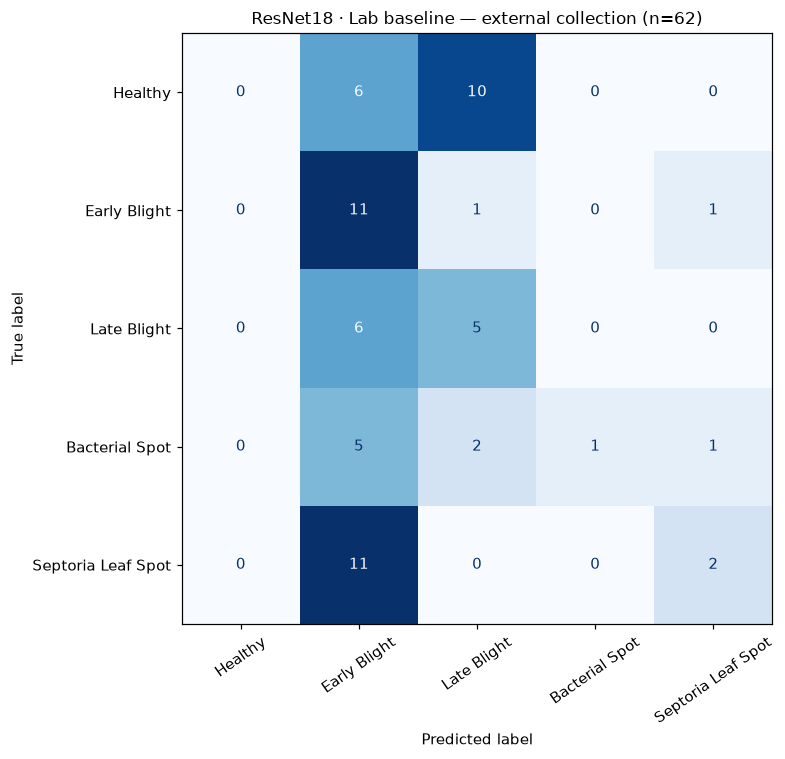

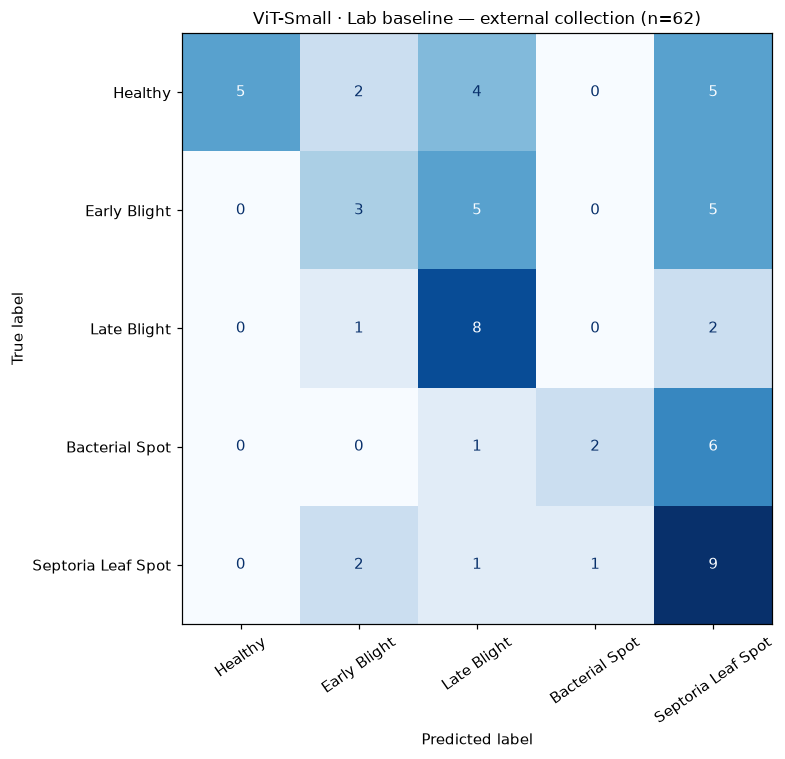

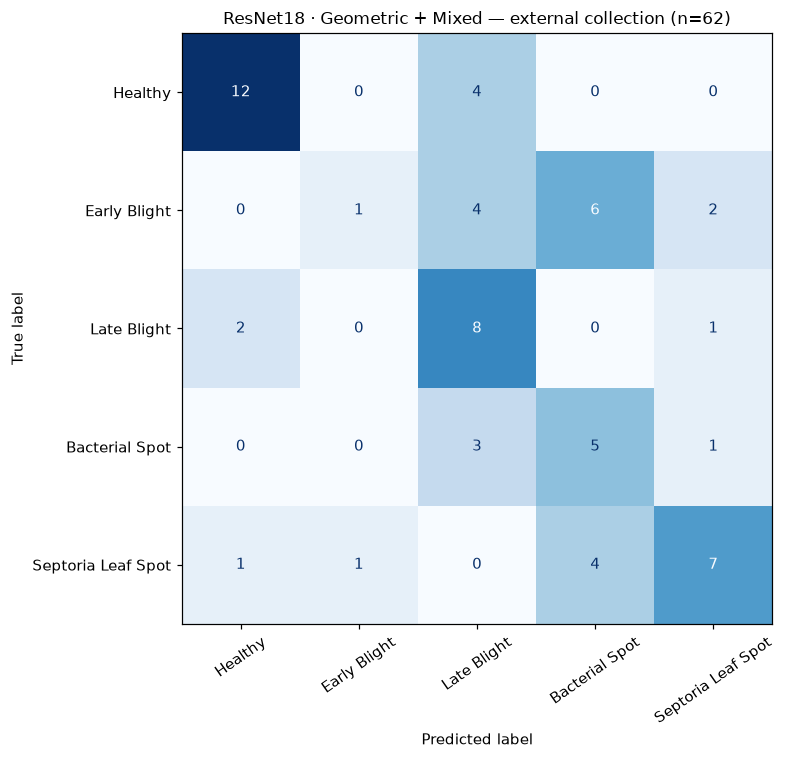

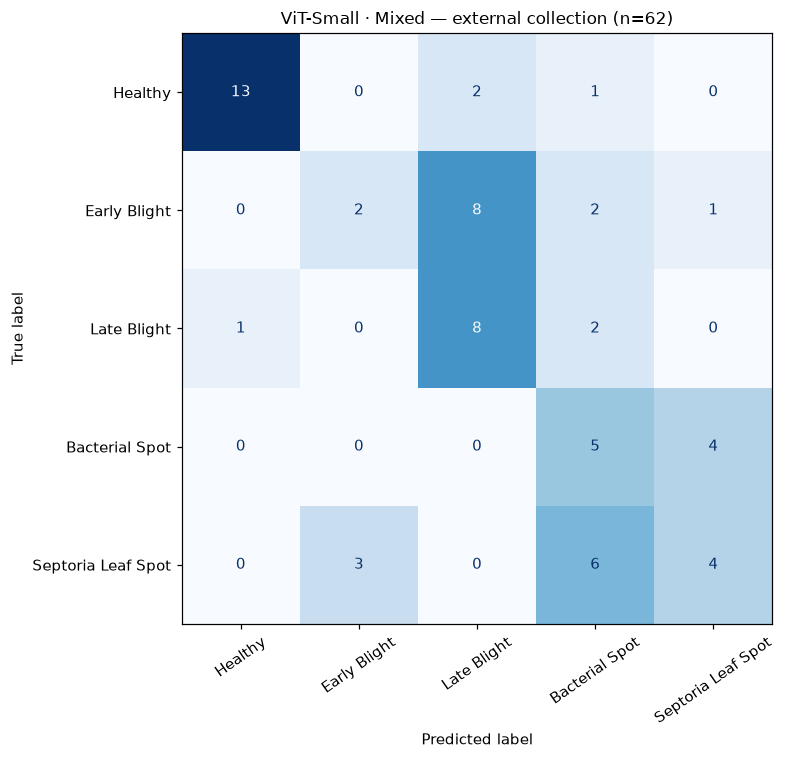

In [19]:
for key, result in prediction_frames.items():
    matrix = confusion_matrix(result.label_id, result.predicted_label_id, labels=LABEL_IDS)
    assert matrix.sum() == 62
    assert np.array_equal(matrix.sum(axis=1), manifest.label_id.value_counts().sort_index().to_numpy())
    assert np.isclose(np.trace(matrix) / matrix.sum(), summary.set_index("model_key").loc[key, "accuracy"])
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUTPUT_ROOT / f"confusion_{key}.csv")
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=35,
    )
    ax.set_title(f"{MODEL_SPECS[key]['model']} — external collection (n=62)")
    fig.tight_layout()
    fig.savefig(OUTPUT_ROOT / f"confusion_{key}.png", dpi=160)
    plt.show()
    plt.close(fig)

### Acquisition and image-type subgroups

The subgroup tables report correct counts over the number of images in each subgroup. The single potted
example is kept separate. Differences between image types are descriptive: class and
source composition differ, and crops are not paired with retained original images.
Full source × image-type and class × image-type metrics are saved in the output CSV.

In [20]:
subgroup_rows = []
for key, result in prediction_frames.items():
    for fields in [("source",), ("source_stratum",), ("image_type",),
                   ("source_stratum", "image_type"), ("class_name", "image_type")]:
        for values, group in result.groupby(list(fields), sort=True, dropna=False):
            values = values if isinstance(values, tuple) else (values,)
            subgroup_rows.append({
                "model_key": key, "model": MODEL_SPECS[key]["model"],
                "grouping": " × ".join(fields),
                "subgroup": " | ".join(map(str, values)),
                "represented_classes": int(group.label_id.nunique()),
                "class_counts": json.dumps(group.class_name.value_counts().to_dict(), sort_keys=True),
                "sample_size_note": "tiny (n<5)" if len(group) < 5 else "descriptive only",
                **score_predictions(group),
            })
subgroups = pd.DataFrame(subgroup_rows)
subgroups.to_csv(OUTPUT_ROOT / "subgroup_metrics.csv", index=False)

subgroups["correct_over_images"] = subgroups.correct.astype(str) + "/" + subgroups.images.astype(str)
for grouping in ("source_stratum", "image_type"):
    display(subgroups.loc[subgroups.grouping.eq(grouping)].pivot(
        index="subgroup", columns="model", values="correct_over_images"
    ).reindex(columns=summary.model))

model,ResNet18 · Lab baseline,ViT-Small · Lab baseline,ResNet18 · Geometric + Mixed,ViT-Small · Mixed
subgroup,,,,
self_collected_natural_context,0/16,5/16,12/16,13/16
web_leaf_photo,19/45,22/45,21/45,19/45
web_potted_experimental,0/1,0/1,0/1,0/1


model,ResNet18 · Lab baseline,ViT-Small · Lab baseline,ResNet18 · Geometric + Mixed,ViT-Small · Mixed
subgroup,,,,
cropped,3/18,9/18,9/18,10/18
multi_leaf,15/39,14/39,22/39,20/39
single_leaf,1/5,4/5,2/5,2/5


## Comparison with previous experiments

The saved notebook 09 results cover Lab Test (1,692 PlantVillage images) and PlantDoc
Field Dev (92 images). Field Dev selected the adapted checkpoints and remains a
development set. It is not an independent test benchmark. Different sampling, class
composition and annotation processes also limit comparisons with the external collection.

accuracy                     \
partition                    external_collection field_dev lab_test   
model                                                                 
ResNet18 · Lab baseline                   0.3065    0.3261   0.9793   
ViT-Small · Lab baseline                  0.4355    0.4022   0.9947   
ResNet18 · Geometric + Mixed              0.5323    0.4674   0.9297   
ViT-Small · Mixed                         0.5161    0.4022   0.9900   

                                        macro_f1                     
partition                    external_collection field_dev lab_test  
model                                                                
ResNet18 · Lab baseline                   0.2406    0.2355   0.9744  
ViT-Small · Lab baseline                  0.4157    0.2677   0.9938  
ResNet18 · Geometric + Mixed              0.4882    0.4459   0.9140  
ViT-Small · Mixed                         0.4808    0.3872   0.9886

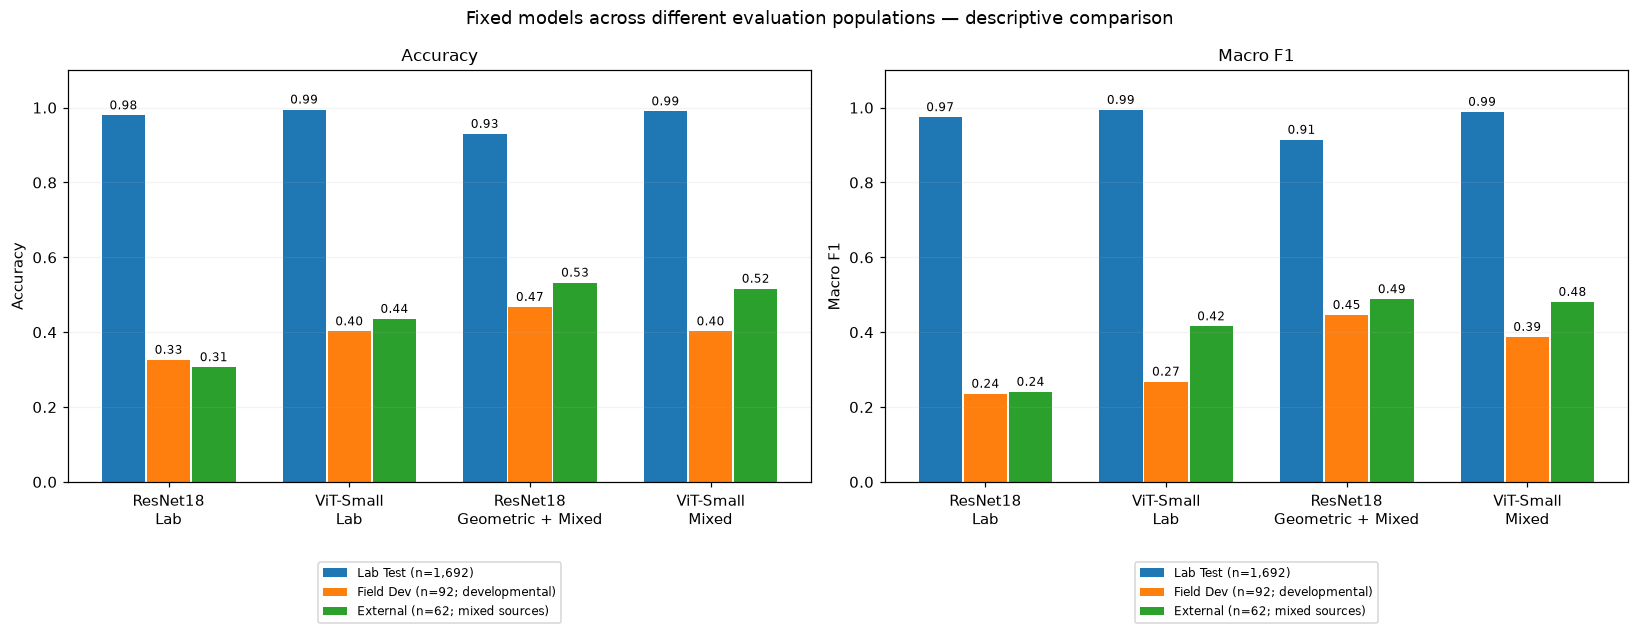

In [21]:
HISTORY_PATH = PROJECT_ROOT / "outputs/final_comparison_development/final_comparison_summary.csv"
HISTORY_SHA256 = sha256_file(HISTORY_PATH) if HISTORY_PATH.is_file() else None
comparison = pd.DataFrame()
if HISTORY_PATH.is_file():
    historical = pd.read_csv(HISTORY_PATH)
    assert not historical.duplicated(["model", "partition"]).any()
    assert set(historical.model) == {spec["model"] for spec in MODEL_SPECS.values()}
    assert set(historical.partition) == {"lab_test", "field_dev"}
    assert historical.loc[historical.partition.eq("lab_test"), "images"].eq(1692).all()
    assert historical.loc[historical.partition.eq("field_dev"), "images"].eq(92).all()
    external = summary.assign(partition="external_collection")
    historical = historical.assign(status="historical_saved", weighted_f1=np.nan)
    comparison = pd.concat([
        historical[["model", "partition", "images", "correct", "accuracy", "macro_f1", "weighted_f1", "status"]],
        external[["model", "partition", "images", "correct", "accuracy", "macro_f1", "weighted_f1", "status"]],
    ], ignore_index=True)
    comparison.to_csv(OUTPUT_ROOT / "historical_comparison.csv", index=False)
    history_table = comparison.pivot(index="model", columns="partition", values=["accuracy", "macro_f1"])
    display(history_table.reindex(summary.model).round(4))
    # NaN external scores remain missing; no zero-height stand-ins for missing models.
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    model_names = [s["model"] for s in MODEL_SPECS.values()]
    short_names = ["ResNet18\nLab", "ViT-Small\nLab", "ResNet18\nGeometric + Mixed", "ViT-Small\nMixed"]
    for ax, metric in zip(axes, ("accuracy", "macro_f1")):
        for offset, partition, label in [(-0.25, "lab_test", "Lab Test (n=1,692)"),
                                          (0, "field_dev", "Field Dev (n=92; developmental)"),
                                          (0.25, "external_collection", "External (n=62; mixed sources)")]:
            values = comparison.loc[comparison.partition.eq(partition)].set_index("model")[metric].reindex(model_names)
            bars = ax.bar(np.arange(4) + offset, values, width=0.24, label=label)
            ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
            if partition == "external_collection":
                for i in np.flatnonzero(values.isna().to_numpy()):
                    ax.text(i + offset, 0.02, "N/A", rotation=90, ha="center", fontsize=8)
        ax.set(xticks=np.arange(4), xticklabels=short_names, ylim=(0, 1.1),
               ylabel=metric.replace("_", " ").title(), title=metric.replace("_", " ").title())
        ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
        ax.grid(axis="y", alpha=0.15)
    fig.suptitle("Fixed models across different evaluation populations — descriptive comparison")
    fig.tight_layout()
    fig.savefig(OUTPUT_ROOT / "historical_comparison.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    assert sha256_file(HISTORY_PATH) == HISTORY_SHA256
else:
    display(Markdown(f"Historical comparison unavailable: missing `{HISTORY_PATH}`."))

## Discussion

Both mixed-domain configurations improve overall external accuracy, but gains are
uneven across classes. Healthy gains and Early Blight losses are especially large
for ResNet18. Notebook 12 investigates these paired changes and representative errors.

This small collection is not a representative independent field benchmark. Its 16
self-collected Healthy images and 46 online disease images cannot separate disease
recognition from acquisition-source cues, and photographs may not be independent.
Field Dev was used for checkpoint selection. The ResNet18 contrast combines geometric
initialization and mixed-domain adaptation; it isolates neither intervention and does
not establish a controlled field-only versus mixed-domain comparison or general
architectural superiority.

## Conclusion

The mixed-domain configurations achieve higher aggregate performance on this collection
while exhibiting class-specific losses. The results support further diagnosis of the fixed
models; confirmation requires new, independently labeled, source-balanced field data.

In [22]:
findings = (
    "# External evaluation findings\n\n" +
    summary[["model", "correct", "images", "accuracy", "macro_f1", "weighted_f1"]].to_csv(index=False) +
    "\nBoth mixed-domain configurations improve aggregate accuracy, with uneven class changes. "
    "Healthy/source confounding and selected, potentially dependent images limit real-world interpretation. "
    "Detailed paired error analysis follows in Notebook 12.\n"
)
(OUTPUT_ROOT / "findings.md").write_text(findings, encoding="utf-8")

681

In [23]:
protocol = {
    "dataset_id": "tomato_field_eval_v1",
    "reference_run": str(REFERENCE_RUN) if REFERENCE_RUN else None,
    "summary_sha256": sha256_file(OUTPUT_ROOT / "model_summary.csv"),
    "prediction_files_sha256": {key: sha256_file(OUTPUT_ROOT / f"predictions_{key}.csv") for key in MODEL_SPECS},
    "task": "Notebook 11 — external evaluation only", "run_id": RUN_ID,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "git_commit": subprocess.check_output(["git", "-C", str(PROJECT_ROOT), "rev-parse", "HEAD"], text=True).strip(),
    "working_tree_status": subprocess.check_output(["git", "-C", str(PROJECT_ROOT), "status", "--short"], text=True),
    "python": platform.python_version(), "versions": VERSIONS, "device": str(DEVICE),
    "seed": 42, "batch_sizes": {key: spec["batch_size"] for key, spec in MODEL_SPECS.items()},
    "manifest_sha256": MANIFEST_SHA256, "class_mapping": LABEL_MAP,
    "image_sha256": dict(zip(manifest.image_id, manifest.sha256)),
    "historical_split_sha256": SPLIT_HASHES,
    "existing_validator_status": AUDIT_STATUS,
    "historical_summary_sha256": HISTORY_SHA256,
    "model_status": summary[["model_key", "status", "detail", "images"]].to_dict("records"),
    "checkpoints_and_preprocessing": provenance_records,
    "complete_four_model_evaluation": summary.status.eq("evaluated").all().item(),
    "inference": "float32, eval, inference_mode, manifest order, five-class argmax; no TTA",
    "macro_f1_labels": LABEL_IDS, "undefined_metric_policy": "zero_division=0",
    "training_or_tuning_performed": False, "historical_inference_performed": False,
    "third_party_images_embedded_in_notebook": False,
    "limitations": ["source/class confounding", "small selected mixed-source dataset",
                    "image-level dependence", "annotation and residual overlap uncertainty",
                    "Field Dev is developmental", "uncalibrated softmax confidence"],
}
(OUTPUT_ROOT / "evaluation_protocol.json").write_text(json.dumps(protocol, indent=2, default=str), encoding="utf-8")
for path, checksum in [(DATA_ROOT / "manifest.csv", MANIFEST_SHA256),
                       *[(SPLITS_DIR / f"{name}.csv", digest) for name, digest in SPLIT_HASHES.items()]]:
    assert sha256_file(path) == checksum, f"Input changed during evaluation: {path}"
print("Saved evaluation:", OUTPUT_ROOT.relative_to(PROJECT_ROOT))

Saved evaluation: outputs/external_evaluation/tomato_field_eval_v1/20261125_163347_4ca8183f
